# Papal visits: does the Vatican pursue a geopolitical objective?

Following Pope Leo's visit to France in Fall 2026 and given the media coverage it received, we decided to investigate the Vatican's diplomacy and to determine whether it pursues a geopolitical goal. To do this, we first analysed the countries visited by John-Paul II, Benedict XVI and Francis. We cross the list of countries visited by these popes with the religious composition of these countries and their level of development.

Questions:

1. **Who do the popes speak to?** Are the visited countries mostly Catholic, or at least more Catholic than the world average?
2. **Growth or decline?** Do the popes go where Catholicism is growing or where it is declining?
3. **Development**: do they rather go to rich countries or to poor countries?

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import s3fs

fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})

POPES = ["John-Paul II", "Benedict XVI", "Francis"]
# Start and end of each pontificate
PONTIFICATES = {"John-Paul II": (1978, 2005), "Benedict XVI": (2005, 2013), "Francis": (2013, 2025)}

## 1. The data

| Table | Source | Content | Years |
| --- | --- | --- | --- |
| Trips | vatican.va (scripts in `acquisition/`) | one row per (trip, country) | 1979-2024 |
| Religions and population | Religious Characteristics of States Dataset, Demographics v. 2.0 (RCS-Dem 2.0), SPSS file | population and share of each religion, **including Catholics** | every year, up to 2015 |
| GDP, region, income | World Bank | | 1960-2024 |

### The trips

In [2]:
with fs.open("avibert/diffusion/df_trips_countries.parquet", "rb") as f:
    trips = pd.read_parquet(f)

trips = trips.rename(columns={"Pope": "pope", "Year": "year", "Place": "trip",
                              "Country": "country", "ISO3": "iso3"})
trips["year"] = trips["year"].astype(int)
trips.head()

,pope,year,trip,country,iso3
0,John-Paul II,1979,Ireland,Ireland,IRL
1,John-Paul II,1979,Poland,Poland,POL
2,John-Paul II,1979,"Dominican Republic, Mexico and Bahamas",Dominican Republic,DOM
3,John-Paul II,1979,"Dominican Republic, Mexico and Bahamas",Mexico,MEX
4,John-Paul II,1979,"Dominican Republic, Mexico and Bahamas",Bahamas,BHS


### The religions: RCS-Dem 2.0

One row per country and per year. The columns ending in `PC` are shares of the population (in %), `TOTPP` is the total population. We keep the main religions and the detail of Christians. The rest of the population is put in an `other_religions` column (Chinese folk religions, African religions, syncretic Christians...), except the people whose religion is unknown (`UNKPC`). Be careful: `CHRPC` (all Christians) already contains `CATPC` (Catholics). To find the majority religion, we must only compare the main religions, otherwise we mix levels.

In [3]:
FILE_RCS = ("avibert/diffusion/Religious Characteristics of States Dataset Project - "
            "Demographics v. 2.0 (RCS-Dem 2.0), COUNTRIES ONLY.SAV")
with fs.open(FILE_RCS, "rb") as f:
    rcs_raw = pd.read_spss(f)

# West Germany (1945-1989) has no ISO3 code in RCS-Dem: we give it the code of Germany
rcs_raw.loc[rcs_raw["ABBREV"] == "GFR", "ISO3"] = "DEU"

religions = pd.DataFrame({
    "iso3": rcs_raw["ISO3"].astype(str).str.strip(),
    "year": rcs_raw["YEAR"],
    "population": rcs_raw["TOTPP"],
    "christians": rcs_raw["CHRPC"],
    "muslims": rcs_raw["MUSPC"],
    "jews": rcs_raw["JEWPC"],
    "buddhists": rcs_raw["BUDPC"],
    "hindus": rcs_raw["HINPC"],
    "no_religion": rcs_raw["NREPC"],
    "catholics": rcs_raw["CATPC"],
    "protestants": rcs_raw["PRTPC"],
    "orthodox": rcs_raw["ORTPC"],
    "unknown": rcs_raw["UNKPC"],
})

# Other religions = what is left when we remove the main religions and the unknown
main_religions = ["christians", "muslims", "jews", "buddhists", "hindus", "no_religion"]
religions["other_religions"] = 100 - religions[main_religions].sum(axis=1) - religions["unknown"].fillna(0)
# Small negative values come from rounding in the data: we put them to 0
religions["other_religions"] = religions["other_religions"].clip(lower=0)
# If a country has no data on religions, the other religions are unknown too
religions.loc[religions["christians"].isna(), "other_religions"] = np.nan
# Some old states have no ISO3 code: we remove them
religions = religions[religions["iso3"] != ""]
religions = religions.dropna(subset=["year"])
religions["year"] = religions["year"].astype(int)
religions.describe()

,year,population,christians,muslims,jews,buddhists,hindus,no_religion,catholics,protestants,orthodox,unknown,other_religions
count,38311.000000,3.830800e+04,38299.000000,37775.000000,37402.000000,38051.000000,38192.000000,37775.000000,37861.000000,38083.000000,38171.000000,38246.000000,38299.000000
mean,1925.824306,1.364707e+07,57.827312,18.811760,0.641117,2.839833,1.598237,2.932650,31.725196,14.353081,6.115997,3.960846,11.752034
std,60.262334,6.569326e+07,39.603469,33.429471,3.355202,12.745987,8.631829,8.507351,37.144596,25.869162,18.274629,9.856128,23.449500
min,1700.000000,1.600000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.053763,0.000000
25%,1888.000000,1.827852e+05,9.307860,0.000000,0.000000,0.000000,0.000000,0.000000,0.759305,0.072461,0.000000,0.000000,0.002382
50%,1934.000000,1.605548e+06,76.626709,0.241803,0.010455,0.000000,0.000000,0.079408,10.033966,1.169620,0.000000,0.610415,0.602972
75%,1975.000000,6.288414e+06,94.259785,17.261446,0.194117,0.029253,0.014789,1.200297,73.126930,14.509243,0.312717,3.612257,8.000001
max,2015.000000,1.409052e+09,100.000000,100.000000,87.719795,90.784126,89.554764,79.623116,100.000000,100.000000,98.856705,100.000000,100.000000


### GDP per capita, region and income (World Bank)

GDP per capita in constant 2015 dollars (indicator `NY.GDP.PCAP.KD`), downloaded from https://data.worldbank.org/indicator/NY.GDP.PCAP.KD (Download, CSV).

In [4]:
FILE_GDP = "avibert/diffusion/API_NY.GDP.PCAP.KD_DS2_en_csv_v2_71952.csv"
with fs.open(FILE_GDP, "rb") as f:
    gdp_raw = pd.read_csv(f, skiprows=4)   # the first 4 lines are a title, not the table

# The last column is empty (the lines end with a comma): we remove the empty columns
gdp_raw = gdp_raw.dropna(axis=1, how="all")

# One column per year -> one row per country and per year
wb = gdp_raw.drop(columns=["Country Name", "Indicator Name", "Indicator Code"])
wb = wb.melt(id_vars="Country Code", var_name="year", value_name="gdp_per_capita")
wb = wb.rename(columns={"Country Code": "iso3"})
wb["year"] = wb["year"].astype(int)
wb.head()

,iso3,year,gdp_per_capita
0,ABW,1960,NaN
1,AFE,1960,1186.271645
2,AFG,1960,NaN
3,AFW,1960,1130.438388
4,AGO,1960,NaN


In [5]:
# Region and income group of each country (current classification)
FILE_COUNTRIES = "avibert/diffusion/Metadata_Country_API_NY.GDP.PCAP.KD_DS2_en_csv_v2_71952.csv"
with fs.open(FILE_COUNTRIES, "rb") as f:
    wb_countries = pd.read_csv(f)

wb_countries = wb_countries[["Country Code", "Region", "IncomeGroup"]]
wb_countries = wb_countries.rename(columns={"Country Code": "iso3", "Region": "region", "IncomeGroup": "income"})
# The aggregates (World, Euro area...) have no region: we remove them
wb_countries = wb_countries.dropna(subset=["region"])
wb_countries.head()

,iso3,region,income
0,ABW,Latin America & Caribbean,High income
2,AFG,Middle East & North Africa,Low income
4,AGO,Sub-Saharan Africa,Lower middle income
5,ALB,Europe & Central Asia,Upper middle income
6,AND,Europe & Central Asia,High income


### Join the trips with the data of the closest year

RCS-Dem stops in 2015. For each visit, we take the closest observation (`merge_asof`), with at most 10 years of difference, and we keep the gap in years to check it. For the visits after 2015 (Francis), we therefore use the 2015 data.

In [6]:
religions = religions.rename(columns={"year": "year_religion"}).sort_values("year_religion")

visits = pd.merge_asof(
    trips.sort_values("year"),
    religions,
    left_on="year", right_on="year_religion", by="iso3",
    direction="nearest", tolerance=10,
)
visits["gap_religion"] = visits["year_religion"] - visits["year"]

In [7]:
# GDP: closest year, at most 5 years of difference
wb_sorted = wb.rename(columns={"year": "year_wb"}).sort_values("year_wb")
visits = pd.merge_asof(visits.sort_values("year"), wb_sorted,
                       left_on="year", right_on="year_wb", by="iso3",
                       direction="nearest", tolerance=5)
visits = visits.merge(wb_countries, on="iso3", how="left")

# Majority religion: we only compare the main religions and the other religions
majority_columns = main_religions + ["other_religions"]
# (dropna: we only compute the majority for the countries that have data)
visits["majority"] = visits[majority_columns].dropna(how="all").idxmax(axis=1)

### Check the join

In [8]:
# For each pope: how many visits without data, and what is the average gap in years?
visits.groupby("pope").agg(
    nb_visits=("iso3", "size"),
    no_religion_data=("christians", lambda x: x.isna().sum()),
    no_catholic_data=("catholics", lambda x: x.isna().sum()),
    mean_gap_religion=("gap_religion", lambda x: x.abs().mean()),
).round(1)

,nb_visits,no_religion_data,no_catholic_data,mean_gap_religion
pope,,,,
Benedict XVI,26,0,0,0.0
Francis,70,0,0,3.7
John-Paul II,200,0,0,0.0


In [9]:
# Visited countries for which we found no religious data
visits.loc[visits["christians"].isna(), ["pope", "year", "country", "iso3"]]

,pope,year,country,iso3


In [10]:
# Visits after 2015: the religious data is older than the trip
visits.loc[visits["year"] > 2015].groupby("pope")["gap_religion"].describe()

,count,mean,std,min,25%,50%,75%,max
pope,,,,,,,,
Francis,53.0,-4.886792,2.743246,-9.0,-8.0,-4.0,-3.0,-1.0


In [11]:
# Visited countries where the other religions are the majority
visits.loc[visits["majority"] == "other_religions", ["pope", "year", "country", "christians", "other_religions"]].round(1)

,pope,year,country,christians,other_religions
9,John-Paul II,1980,Burkina Faso,11.9,44.0
12,John-Paul II,1980,Ivory Coast,25.8,38.6
30,John-Paul II,1982,Benin,27.5,50.4
42,John-Paul II,1983,Haiti,29.8,50.3
53,John-Paul II,1985,Togo,37.8,47.7
84,John-Paul II,1988,Botswana,23.9,59.6
86,John-Paul II,1988,Eswatini,26.6,46.5
87,John-Paul II,1988,Mozambique,36.6,44.2
115,John-Paul II,1990,Guinea-Bissau,10.6,51.8


## 2. Overview of the trips

In [12]:
# One trip = one trip title for a pope and a year
trips["trip_id"] = trips["pope"] + " " + trips["year"].astype(str) + " " + trips["trip"]

overview = trips.groupby("pope").agg(
    nb_trips=("trip_id", "nunique"),
    nb_visits=("iso3", "size"),
    nb_countries=("iso3", "nunique"),
).loc[POPES]
overview["pontificate_length"] = [end - start for start, end in PONTIFICATES.values()]
overview["trips_per_year"] = (overview["nb_trips"] / overview["pontificate_length"]).round(1)
overview

,nb_trips,nb_visits,nb_countries,pontificate_length,trips_per_year
pope,,,,,
John-Paul II,105,200,127,27,3.9
Benedict XVI,24,26,22,8,3.0
Francis,48,70,64,12,4.0


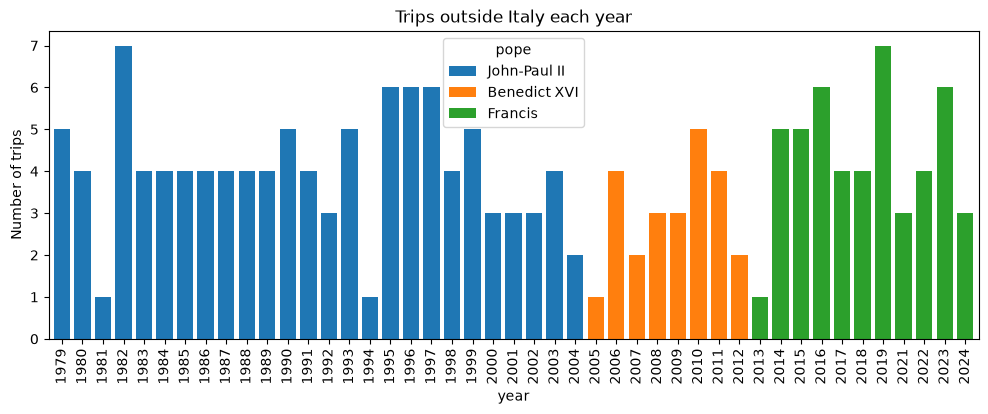

In [13]:
per_year = trips.groupby(["year", "pope"])["trip_id"].nunique().unstack(fill_value=0)[POPES]
per_year.plot.bar(stacked=True, figsize=(12, 4), width=0.8)
plt.ylabel("Number of trips")
plt.title("Trips outside Italy each year")
plt.show()

John-Paul II and Francis have been more active than Benedict XVI with 4 trips per year on average for the first two against 3 for the latter. John-Paul II took advantage of his youth since he was elected at only 58. Francis, who was almost the same age as Benedict XVI, shows a strong wilingness to visit countries bespite his age. He traveled more than John-Paul II at the same age.

In [14]:
# The most visited countries
trips.groupby("country")["trip_id"].nunique().sort_values(ascending=False).head(15)

country
France           11
Poland           11
Spain             8
United States     8
Mexico            7
Portugal          7
Germany           6
Brazil            5
Austria           4
Malta             4
Slovakia          4
Switzerland       4
Canada            4
Kenya             4
Hungary           4
Name: trip_id, dtype: int64

### Maps of the visited countries

In [15]:
world = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip")
world = world[["NAME", "ISO_A3_EH", "geometry"]].rename(columns={"NAME": "name", "ISO_A3_EH": "iso3"})
world = world[world["name"] != "Antarctica"]
world.head()

,name,iso3,geometry
0,Zimbabwe,ZWE,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,ZMB,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,YEM,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."
3,Vietnam,VNM,"MULTIPOLYGON (((104.06396 10.39082, 104.08301 ..."
4,Venezuela,VEN,"MULTIPOLYGON (((-60.82119 9.13838, -60.94141 9..."


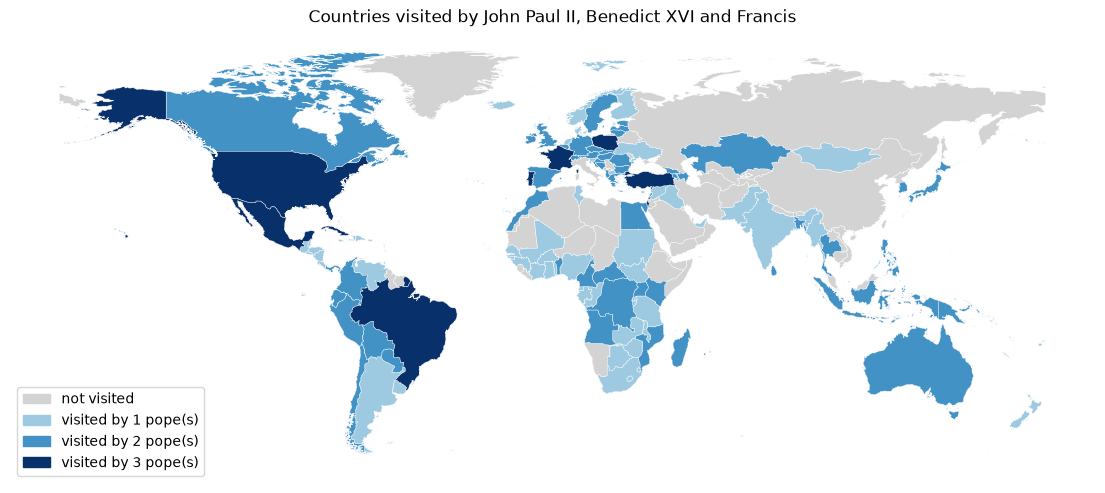

In [16]:
# Map 1: number of popes (among the three) who visited each country
nb_popes = trips.groupby("iso3")["pope"].nunique().reset_index(name="nb_popes")
world_popes = world.merge(nb_popes, on="iso3", how="left")
world_popes["nb_popes"] = world_popes["nb_popes"].fillna(0)

colors = {1: "#9ecae1", 2: "#4292c6", 3: "#08306b"}

fig, ax = plt.subplots(figsize=(14, 7))
world_popes.plot(ax=ax, color="lightgrey", edgecolor="white", linewidth=0.3)
for n, color in colors.items():
    world_popes[world_popes["nb_popes"] == n].plot(ax=ax, color=color, edgecolor="white", linewidth=0.3)

legend = [Patch(color="lightgrey", label="not visited")]
for n, color in colors.items():
    legend.append(Patch(color=color, label=f"visited by {n} pope(s)"))
ax.legend(handles=legend, loc="lower left")
ax.set_title("Countries visited by John Paul II, Benedict XVI and Francis")
ax.set_axis_off()
plt.show()

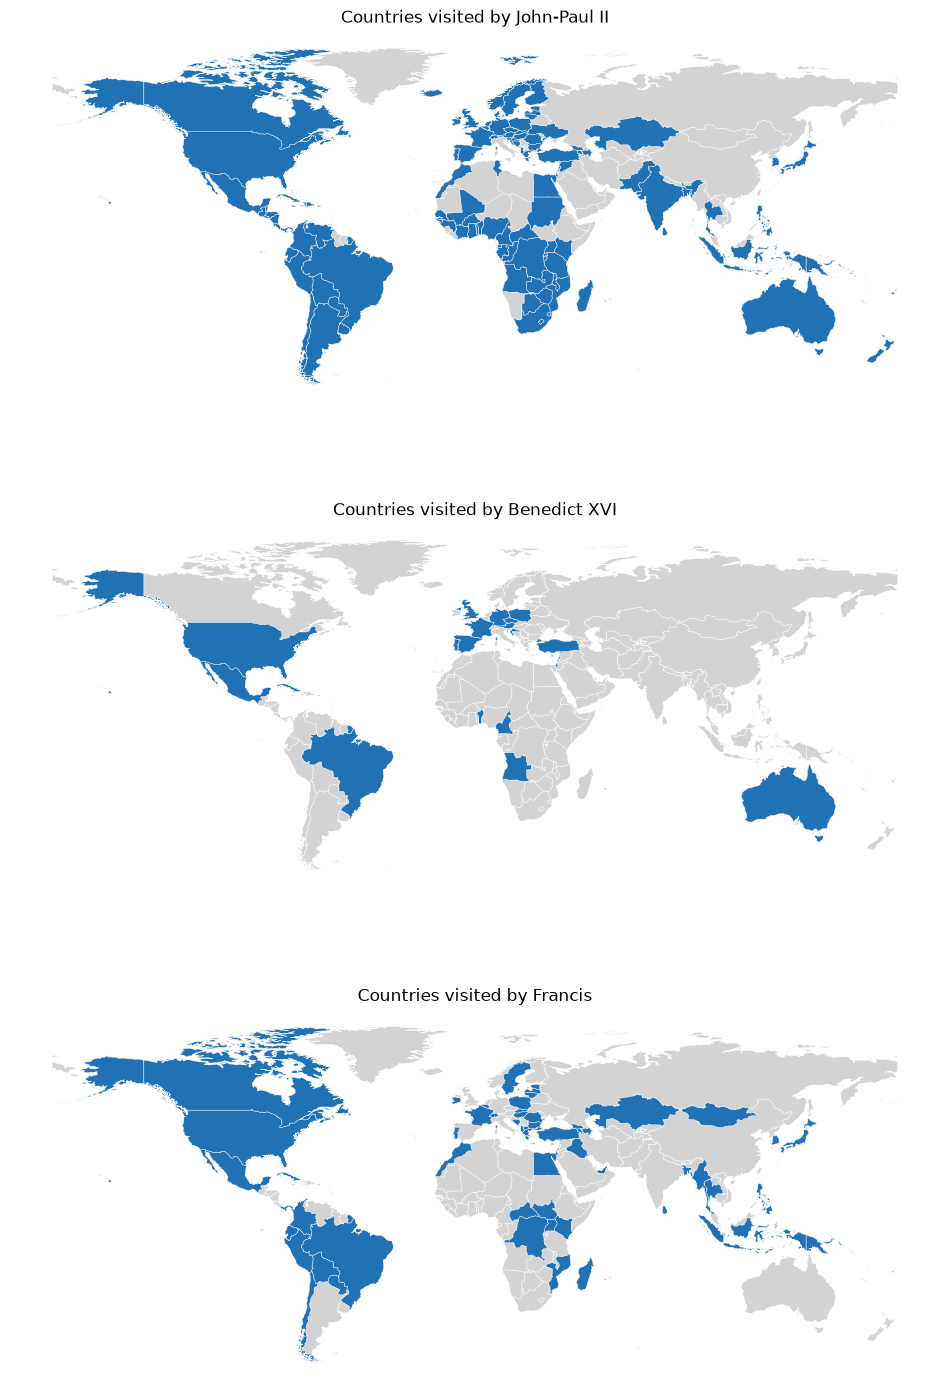

In [17]:
# Maps 2 to 4: the countries visited by each pope
fig, axes = plt.subplots(3, 1, figsize=(12, 18))
for ax, pope in zip(axes, POPES):
    visited_iso3 = trips.loc[trips["pope"] == pope, "iso3"]
    world.plot(ax=ax, color="lightgrey", edgecolor="white", linewidth=0.3)
    world[world["iso3"].isin(visited_iso3)].plot(ax=ax, color="#2171b5", edgecolor="white", linewidth=0.3)
    ax.set_title(f"Countries visited by {pope}")
    ax.set_axis_off()
plt.show()

## 3. Who do the popes speak to?

To compare the visited countries with the others, we build a table with **one row per pope and per country of the world**, and a column `visited` which is True if the pope went there. Each country is counted once, even if the pope went there several times.

We use the religious data of the middle year of the pontificate (2015 for Francis, because RCS-Dem stops in 2015).

In [18]:
rows = []
for pope, (start, end) in PONTIFICATES.items():
    middle_year = min((start + end) // 2, 2015)
    table = religions[religions["year_religion"] == middle_year].copy()
    table["pope"] = pope
    visited_iso3 = trips.loc[trips["pope"] == pope, "iso3"]
    table["visited"] = table["iso3"].isin(visited_iso3)
    rows.append(table)

countries = pd.concat(rows, ignore_index=True)
countries["majority"] = countries[majority_columns].dropna(how="all").idxmax(axis=1)

# Number of visited countries and number of countries for each pope
countries.groupby("pope")["visited"].agg(["sum", "size"]).loc[POPES]

,sum,size
pope,,
John-Paul II,127,235
Benedict XVI,22,234
Francis,64,233


### Share of Catholics in the visited countries

In [19]:
visited_countries = countries[countries["visited"]]
visited_countries.groupby("pope")["catholics"].describe().loc[POPES].round(1)

,count,mean,std,min,25%,50%,75%,max
pope,,,,,,,,
John-Paul II,126.0,38.1,33.6,0.0,5.5,26.5,77.1,95.2
Benedict XVI,22.0,44.9,31.2,0.1,23.0,40.5,70.3,93.1
Francis,64.0,33.0,32.1,0.0,1.5,24.2,63.4,92.6


In [20]:
# Same thing for the countries that were not visited, to compare
countries[~countries["visited"]].groupby("pope")["catholics"].describe().loc[POPES].round(1)

,count,mean,std,min,25%,50%,75%,max
pope,,,,,,,,
John-Paul II,108.0,20.6,29.0,0.0,0.6,5.4,28.4,97.4
Benedict XVI,212.0,26.3,29.7,0.0,1.3,11.3,50.7,98.7
Francis,169.0,25.3,28.5,0.0,2.1,11.3,44.5,99.4


### How many visited countries are Christian or Catholic?

- Christian: Christians are the largest religion of the country (`majority` column).
- Catholic: Catholics are more than 50 % of the population.

In [21]:
visited_countries = countries[countries["visited"]].copy()
visited_countries["christian_majority"] = visited_countries["majority"] == "christians"
visited_countries["catholic_majority"] = visited_countries["catholics"] > 50

result = visited_countries.groupby("pope")[["christian_majority", "catholic_majority"]].sum()
result["nb_visited_countries"] = visited_countries.groupby("pope").size()
result["% christian_majority"] = (result["christian_majority"] / result["nb_visited_countries"] * 100).round(1)
result["% catholic_majority"] = (result["catholic_majority"] / result["nb_visited_countries"] * 100).round(1)
result.loc[POPES]

,christian_majority,catholic_majority,nb_visited_countries,% christian_majority,% catholic_majority
pope,,,,,
John-Paul II,91,48,127,71.7,37.8
Benedict XVI,18,10,22,81.8,45.5
Francis,43,22,64,67.2,34.4


### How many visited countries are more Catholic than the others?

For each pope, we compute the average share of Catholics in the countries he did **not** visit, and we count the visited countries above this average.

In [22]:
results = []
for pope in POPES:
    table = countries[(countries["pope"] == pope) & countries["catholics"].notna()]
    visited = table[table["visited"]]
    not_visited = table[~table["visited"]]

    mean_not_visited = not_visited["catholics"].mean()
    with_population = table[table["population"].notna()]
    world_share = np.average(with_population["catholics"], weights=with_population["population"])

    results.append({
        "pope": pope,
        "mean visited": visited["catholics"].mean(),
        "mean not visited": mean_not_visited,
        "world share (weighted)": world_share,
        "nb visited above mean not visited": (visited["catholics"] > mean_not_visited).sum(),
        "% visited above mean not visited": (visited["catholics"] > mean_not_visited).mean() * 100,
    })

pd.DataFrame(results).set_index("pope").round(1)

,mean visited,mean not visited,world share (weighted),nb visited above mean not visited,% visited above mean not visited
pope,,,,,
John-Paul II,38.1,20.6,16.2,72,57.1
Benedict XVI,44.9,26.3,15.2,14,63.6
Francis,33.0,25.3,15.0,31,48.4


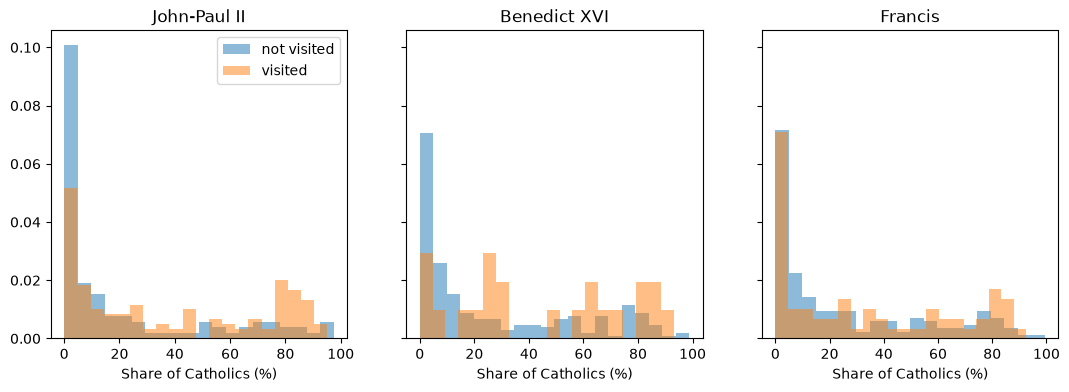

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, pope in zip(axes, POPES):
    table = countries[countries["pope"] == pope]
    ax.hist(table.loc[~table["visited"], "catholics"].dropna(), bins=20, alpha=0.5, label="not visited", density=True)
    ax.hist(table.loc[table["visited"], "catholics"].dropna(), bins=20, alpha=0.5, label="visited", density=True)
    ax.set_title(pope)
    ax.set_xlabel("Share of Catholics (%)")
axes[0].legend()
plt.show()

In [24]:
# Differences between regions (visits, with the data of the year of the visit)
visits.groupby(["region", "pope"])["catholics"].mean().unstack()[POPES].round(1)

pope,John-Paul II,Benedict XVI,Francis
region,,,
East Asia & Pacific,26.2,25.6,22.1
Europe & Central Asia,53.8,48.0,31.4
Latin America & Caribbean,71.9,65.7,71.5
Middle East & North Africa,25.3,41.0,16.9
North America,29.8,22.5,28.8
South Asia,2.1,NaN,3.2
Sub-Saharan Africa,27.7,36.9,35.4


## 4. How Christian population evolves in visited countries ?

For each visit, we compute the change of the share of Catholics in the visited country during the **5 years before the visit** (in percentage points). We compare it with the change of the **average share of Catholics of all countries** during the same 5 years (each country counts for one, like in part 3).

RCS-Dem stops in 2015: for the visits after 2015, we use the change between 2010 and 2015.

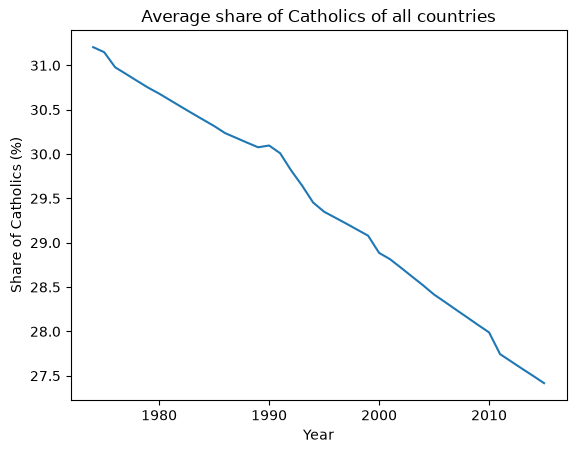

In [25]:
# Average share of Catholics of all countries, each year
mean_catholics = religions.groupby("year_religion")["catholics"].mean().reset_index(name="mean_catholics")

# The first visit is in 1979, so the first year we need is 1974
mean_catholics[mean_catholics["year_religion"] >= 1974].plot(x="year_religion", y="mean_catholics", legend=False)
plt.xlabel("Year")
plt.ylabel("Share of Catholics (%)")
plt.title("Average share of Catholics of all countries")
plt.show()

In [26]:
# The 5 years before the visit (the data stops in 2015)
visits["year_end"] = visits["year"].clip(upper=2015)
visits["year_start"] = visits["year_end"] - 5

# Share of Catholics in the visited country at the start and at the end
share_start = religions[["iso3", "year_religion", "catholics"]].rename(
    columns={"year_religion": "year_start", "catholics": "catholics_start"})
share_end = religions[["iso3", "year_religion", "catholics"]].rename(
    columns={"year_religion": "year_end", "catholics": "catholics_end"})
visits = visits.merge(share_start, on=["iso3", "year_start"], how="left")
visits = visits.merge(share_end, on=["iso3", "year_end"], how="left")

# Average share of Catholics of all countries at the start and at the end
mean_start = mean_catholics.rename(columns={"year_religion": "year_start", "mean_catholics": "mean_start"})
mean_end = mean_catholics.rename(columns={"year_religion": "year_end", "mean_catholics": "mean_end"})
visits = visits.merge(mean_start, on="year_start", how="left")
visits = visits.merge(mean_end, on="year_end", how="left")

# Changes in percentage points
visits["change_country"] = visits["catholics_end"] - visits["catholics_start"]
visits["change_mean"] = visits["mean_end"] - visits["mean_start"]
visits["change_vs_mean"] = visits["change_country"] - visits["change_mean"]

# Check: how many visits without a change?
visits.groupby("pope")["change_country"].apply(lambda x: x.isna().sum())

pope
Benedict XVI    0
Francis         0
John-Paul II    1
Name: change_country, dtype: int64

### Descriptive statistics

In [27]:
changes = visits.dropna(subset=["change_country"]).copy()
changes.groupby("pope")["change_country"].describe().loc[POPES].round(2)

,count,mean,std,min,25%,50%,75%,max
pope,,,,,,,,
John-Paul II,199.0,-0.60,2.13,-8.15,-1.42,-0.15,0.30,10.69
Benedict XVI,26.0,-1.23,2.09,-8.56,-1.75,-0.80,-0.08,2.23
Francis,70.0,-0.25,2.51,-7.78,-1.11,-0.02,0.32,10.56


In [28]:
# Average change in the visited countries and in all countries
changes.groupby("pope")[["change_country", "change_mean", "change_vs_mean"]].mean().loc[POPES].round(2)

,change_country,change_mean,change_vs_mean
pope,,,
John-Paul II,-0.60,-0.43,-0.18
Benedict XVI,-1.23,-0.49,-0.74
Francis,-0.25,-0.57,0.32


In [29]:
# Share of visits where Catholicism was growing, and growing faster than on average
changes["growing"] = changes["change_country"] > 0
changes["faster_than_mean"] = changes["change_vs_mean"] > 0

(changes.groupby("pope")[["growing", "faster_than_mean"]].mean() * 100).loc[POPES].round(1)

,growing,faster_than_mean
pope,,
John-Paul II,42.2,56.3
Benedict XVI,19.2,34.6
Francis,44.3,65.7


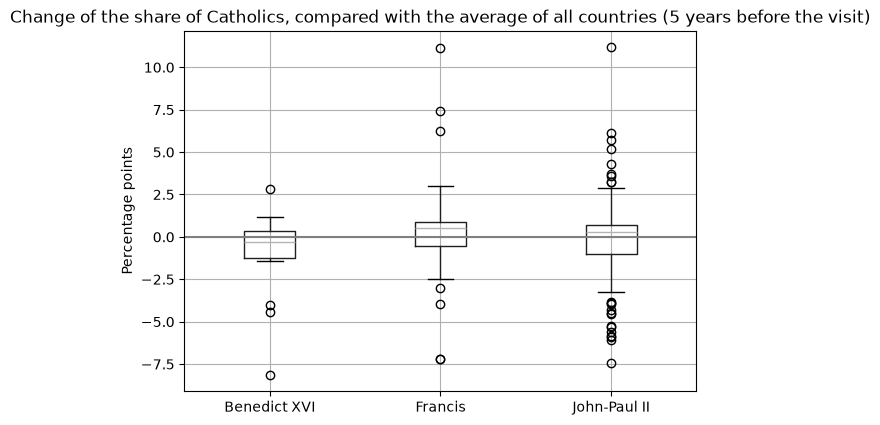

In [30]:
changes.boxplot(column="change_vs_mean", by="pope")
plt.axhline(0, color="grey")
plt.title("Change of the share of Catholics, compared with the average of all countries (5 years before the visit)")
plt.suptitle("")
plt.xlabel("")
plt.ylabel("Percentage points")
plt.show()

## 5. Development: do the popes go to rich or poor countries?

For each visit, we divide the GDP per capita of the visited country by the world GDP per capita of the same year (World Bank, code `WLD`). A ratio above 1 means that the visited country is richer than the world average. We use the median and not the mean, because a few very rich countries (Luxembourg, Switzerland...) pull the mean up.

In [31]:
# World GDP per capita each year (the World Bank gives it with the code "WLD")
world_gdp = wb[wb["iso3"] == "WLD"][["year", "gdp_per_capita"]]
world_gdp = world_gdp.rename(columns={"gdp_per_capita": "world_gdp_per_capita"})

visits = visits.merge(world_gdp, on="year", how="left")
visits["gdp_ratio"] = visits["gdp_per_capita"] / visits["world_gdp_per_capita"]

# Visits without GDP data
visits.loc[visits["gdp_per_capita"].isna(), ["pope", "year", "country"]]

,pope,year,country
1,John-Paul II,1979,Poland
17,John-Paul II,1981,Guam
24,John-Paul II,1982,San Marino
40,John-Paul II,1983,Poland
52,John-Paul II,1985,Liechtenstein
77,John-Paul II,1987,Poland
102,John-Paul II,1989,Reunion
111,John-Paul II,1990,Curacao
284,Francis,2023,South Sudan


In [32]:
gdp = visits.dropna(subset=["gdp_ratio"]).copy()
gdp["richer_than_world"] = gdp["gdp_ratio"] > 1

gdp_table = gdp.groupby("pope").agg(
    nb_visits=("gdp_ratio", "size"),
    median_gdp_visits=("gdp_per_capita", "median"),
    median_gdp_world=("world_gdp_per_capita", "median"),
    median_ratio=("gdp_ratio", "median"),
    pct_richer_than_world=("richer_than_world", "mean"),
).loc[POPES]
gdp_table["pct_richer_than_world"] = gdp_table["pct_richer_than_world"] * 100
gdp_table.round(2)

,nb_visits,median_gdp_visits,median_gdp_world,median_ratio,pct_richer_than_world
pope,,,,,
John-Paul II,192,4735.93,6741.22,0.70,41.15
Benedict XVI,26,23130.60,9265.53,2.45,73.08
Francis,69,11058.35,10822.57,1.01,50.72


### Number of visits by income group

We use the World Bank income groups. Be careful: it is the current classification, not the one of the year of the visit.

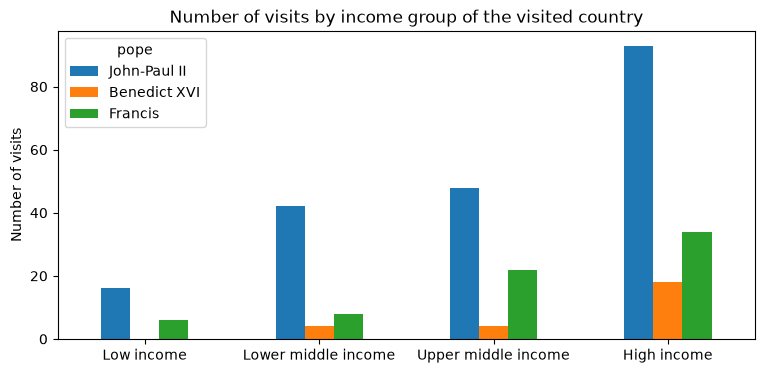

pope,John-Paul II,Benedict XVI,Francis
income,,,
Low income,16,0,6
Lower middle income,42,4,8
Upper middle income,48,4,22
High income,93,18,34


In [34]:
# Number of visits in each income group (from the poorest to the richest)
income_order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
by_income = pd.crosstab(visits["income"], visits["pope"]).loc[income_order, POPES]

by_income.plot.bar(figsize=(9, 4))
plt.xticks(rotation=0)
plt.xlabel("")
plt.ylabel("Number of visits")
plt.title("Number of visits by income group of the visited country")
plt.show()
by_income

In [35]:
# Number of different countries visited in each income group (a country visited twice counts once)
countries_by_income = visits.groupby(["income", "pope"])["iso3"].nunique().unstack(fill_value=0).loc[income_order, POPES]

# Total number of countries in each income group, to compare
countries_by_income["nb_countries"] = wb_countries["income"].value_counts()

# Share of the countries of the group that each pope visited (in %)
for pope in POPES:
    countries_by_income["% " + pope] = (countries_by_income[pope] / countries_by_income["nb_countries"] * 100).round(1)
countries_by_income

pope,John-Paul II,Benedict XVI,Francis,nb_countries,% John-Paul II,% Benedict XVI,% Francis
income,,,,,,,
Low income,14,0,6,25,56.0,0.0,24.0
Lower middle income,31,4,8,47,66.0,8.5,17.0
Upper middle income,33,4,22,59,55.9,6.8,37.3
High income,48,14,28,86,55.8,16.3,32.6
